# NFL Big Data Bowl 2026 — Prediction: Exploratory Data Analysis



In [11]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display

RANDOM_SEED = 55
rng = np.random.default_rng(RANDOM_SEED)
FPS = 10  # Official tracking rate: 10 frames / second

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.max_columns", 35)
pd.set_option("display.width", 130)
print("pandas:", pd.__version__, "| NumPy:", np.__version__)

pandas: 3.1.1 | NumPy: 2.5.4


In [12]:
# EDIT THIS PATH. It may point either to the extracted competition folder or to train/.
DATA_DIR = Path("./nfl-big-data-bowl-2026-prediction")

# First run: start with three weeks; later set to None for all available weeks.
WEEKS_TO_LOAD = [1, 2, 3]  # or None

SAVE_FIGURES = True
FIG_DIR = Path("eda_figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_DIR = DATA_DIR / "train" if (DATA_DIR / "train").is_dir() else DATA_DIR

def save_figure(fig, filename):
    if SAVE_FIGURES:
        target = FIG_DIR / filename
        fig.savefig(target, dpi=170, bbox_inches="tight")
        print(f"Saved: {target.resolve()}")

print("Searching:", TRAIN_DIR)
print("Figures directory:", FIG_DIR.resolve())

Searching: nfl-big-data-bowl-2026-prediction\train
Figures directory: C:\Users\jeast\Documents\UVA\ML_3\Project\eda_figures


 ### Discover and match input/output files



In [13]:
input_files = {
    int(match.group(1)): p
    for p in sorted(TRAIN_DIR.glob("input_2023_w*.csv"))
    if (match := re.fullmatch(r"input_2023_w(\d{2})\.csv", p.name))
}
output_files = {
    int(match.group(1)): p
    for p in sorted(TRAIN_DIR.glob("output_2023_w*.csv"))
    if (match := re.fullmatch(r"output_2023_w(\d{2})\.csv", p.name))
}

if not input_files or not output_files:
    raise FileNotFoundError(
        f"Could not find 2023 weekly input/output files in {TRAIN_DIR}. "
        "Edit DATA_DIR in Code chunk 2 after extracting the Kaggle ZIP."
    )

available_weeks = sorted(set(input_files).intersection(output_files))
missing_pairs = sorted(set(input_files).symmetric_difference(output_files))
if missing_pairs:
    warnings.warn(f"Weeks missing a matching input/output file: {missing_pairs}")

selected_weeks = available_weeks if WEEKS_TO_LOAD is None else [
    w for w in WEEKS_TO_LOAD if w in available_weeks
]
if not selected_weeks:
    raise ValueError(f"None of WEEKS_TO_LOAD={WEEKS_TO_LOAD} has a complete pair. Available: {available_weeks}")

manifest = pd.DataFrame({
    "week": selected_weeks,
    "input_path": [str(input_files[w]) for w in selected_weeks],
    "output_path": [str(output_files[w]) for w in selected_weeks],
})
display(manifest)
print("Weeks selected:", selected_weeks, "| All paired weeks found:", available_weeks)

,week,input_path,output_path
0,1,nfl-big-data-bowl-2026-prediction\train\input_...,nfl-big-data-bowl-2026-prediction\train\output...
1,2,nfl-big-data-bowl-2026-prediction\train\input_...,nfl-big-data-bowl-2026-prediction\train\output...
2,3,nfl-big-data-bowl-2026-prediction\train\input_...,nfl-big-data-bowl-2026-prediction\train\output...


Weeks selected: [1, 2, 3] | All paired weeks found: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]


## Read weekly tracking tables


In [ ]:
input_parts, output_parts = [], []
for w in selected_weeks:
    x = pd.read_csv(input_files[w], low_memory=False)
    y = pd.read_csv(output_files[w], low_memory=False)
    x["week"] = w
    y["week"] = w
    input_parts.append(x)
    output_parts.append(y)
    print(f"Week {w:02d}: {len(x):,} input rows; {len(y):,} output rows")

input_df = pd.concat(input_parts, ignore_index=True)
output_df = pd.concat(output_parts, ignore_index=True)
del input_parts, output_parts

REQ_IN = {
    "week", "game_id", "play_id", "nfl_id", "frame_id", "x", "y", "s", "a", "dir",
    "player_to_predict", "player_role", "player_side", "num_frames_output", "ball_land_x", "ball_land_y",
}
REQ_OUT = {"week", "game_id", "play_id", "nfl_id", "frame_id", "x", "y"}
for name, df, required in (("input", input_df, REQ_IN), ("output", output_df, REQ_OUT)):
    missing = sorted(required - set(df.columns))
    if missing:
        raise ValueError(f"Missing required {name} columns: {missing}. Review the dataset/version.")

#Convert potentially string-encoded booleans to a bool column.
input_df["player_to_predict"] = (
    input_df["player_to_predict"].astype(str).str.strip().str.lower().isin(["true", "1", "yes"])
)

for name, df in (("Input", input_df), ("Output", output_df)):
    print(f"\n{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")
    print(f"Approximate pandas memory: {df.memory_usage(deep=True).sum()/1024**2:.1f} MiB")
    display(df.head(3))

Week 01: 285,714 input rows; 32,088 output rows
Week 02: 288,586 input rows; 32,180 output rows
Week 03: 297,757 input rows; 36,080 output rows

Input: 872,057 rows × 24 columns
Approximate pandas memory: 439.9 MiB


,game_id,play_id,player_to_predict,nfl_id,frame_id,play_direction,absolute_yardline_number,player_name,player_height,player_weight,player_birth_date,player_position,player_side,player_role,x,y,s,a,dir,o,num_frames_output,ball_land_x,ball_land_y,week
0,2023090700,101,False,54527,1,right,42,Bryan Cook,6-1,210,1999-09-07,FS,Defense,Defensive Coverage,52.33,36.94,0.09,0.39,322.40,238.24,21,63.259998,-0.22,1
1,2023090700,101,False,54527,2,right,42,Bryan Cook,6-1,210,1999-09-07,FS,Defense,Defensive Coverage,52.33,36.94,0.04,0.61,200.89,236.05,21,63.259998,-0.22,1
2,2023090700,101,False,54527,3,right,42,Bryan Cook,6-1,210,1999-09-07,FS,Defense,Defensive Coverage,52.33,36.93,0.12,0.73,147.55,240.60,21,63.259998,-0.22,1



Output: 100,348 rows × 7 columns
Approximate pandas memory: 5.4 MiB


,game_id,play_id,nfl_id,frame_id,x,y,week
0,2023090700,101,46137,1,56.22,17.28,1
1,2023090700,101,46137,2,56.63,16.88,1
2,2023090700,101,46137,3,57.06,16.46,1


## Inspect and check for duplicate keys

In [15]:
PLAYER_KEYS = ["week", "game_id", "play_id", "nfl_id"]
PLAY_KEYS = ["week", "game_id", "play_id"]
FRAME_KEYS = PLAYER_KEYS + ["frame_id"]

def schema_report(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100).round(2),
        "n_unique": df.nunique(dropna=True),
    }).sort_values("missing_pct", ascending=False)

print("INPUT SCHEMA")
display(schema_report(input_df))
print("OUTPUT SCHEMA")
display(schema_report(output_df))

print("Unique games:", input_df[["week", "game_id"]].drop_duplicates().shape[0])
print("Unique plays:", input_df[PLAY_KEYS].drop_duplicates().shape[0])
print("Unique input player sequences:", input_df[PLAYER_KEYS].drop_duplicates().shape[0])
print("Unique output player sequences:", output_df[PLAYER_KEYS].drop_duplicates().shape[0])
print("Duplicate input frame keys:", int(input_df.duplicated(FRAME_KEYS).sum()))
print("Duplicate output frame keys:", int(output_df.duplicated(FRAME_KEYS).sum()))

if input_df.duplicated(FRAME_KEYS).any() or output_df.duplicated(FRAME_KEYS).any():
    raise ValueError("Duplicate tracking keys detected; inspect them before merging or scoring.")

INPUT SCHEMA


,dtype,missing_count,missing_pct,n_unique
game_id,int64,0,0.0,48
play_id,int64,0,0.0,1974
player_to_predict,bool,0,0.0,2
nfl_id,int64,0,0.0,938
frame_id,int64,0,0.0,83
play_direction,str,0,0.0,2
absolute_yardline_number,int64,0,0.0,99
player_name,str,0,0.0,938
player_height,str,0,0.0,15
player_weight,int64,0,0.0,124


OUTPUT SCHEMA


,dtype,missing_count,missing_pct,n_unique
game_id,int64,0,0.0,48
play_id,int64,0,0.0,1974
nfl_id,int64,0,0.0,781
frame_id,int64,0,0.0,94
x,float64,0,0.0,11485
y,float64,0,0.0,5190
week,int64,0,0.0,3


Unique games: 48
Unique plays: 2573
Unique input player sequences: 31620
Unique output player sequences: 8396
Duplicate input frame keys: 0
Duplicate output frame keys: 0


## Looking for missing values

Saved: C:\Users\jeast\Documents\UVA\ML_3\Project\eda_figures\01_missing_values.png


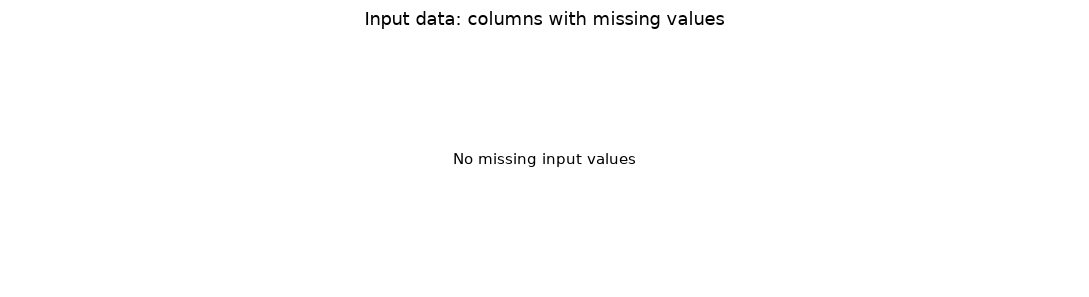

player_to_predict,Not scored,Scored
player_role,,
Defensive Coverage,11336,5823
Other Route Runner,9316,0
Passer,2572,0
Targeted Receiver,0,2573


Saved: C:\Users\jeast\Documents\UVA\ML_3\Project\eda_figures\02_role_prediction_counts.png


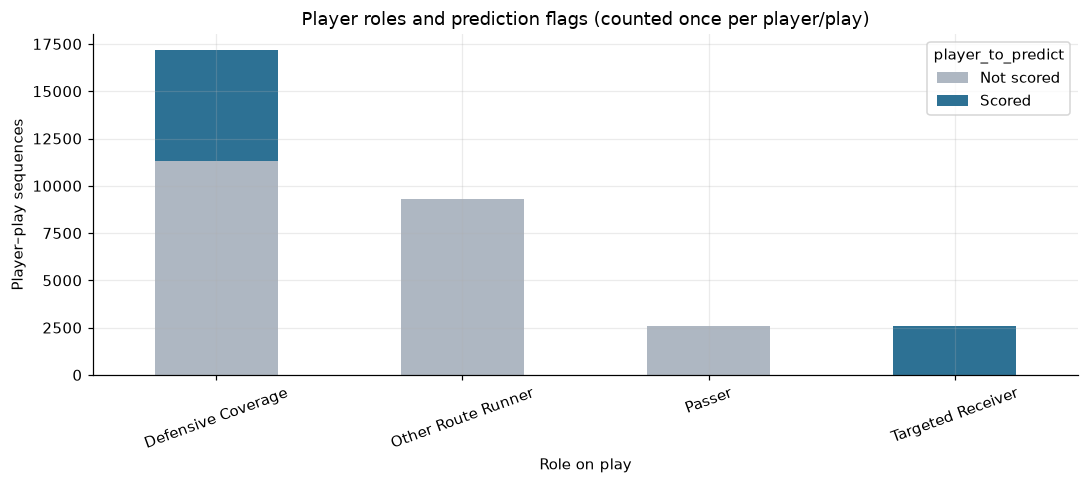

In [16]:
missing_pct = (input_df.isna().mean() * 100).sort_values(ascending=False)
top_missing = missing_pct[missing_pct > 0].head(14)
fig, ax = plt.subplots(figsize=(10, max(2.8, 0.38 * max(1, len(top_missing)))))
if len(top_missing):
    top_missing.sort_values().plot.barh(ax=ax, color="#597da3")
    ax.set_xlabel("Missing values (% of input rows)")
else:
    ax.text(0.5, 0.5, "No missing input values", ha="center", va="center", transform=ax.transAxes)
    ax.set_axis_off()
ax.set_title("Input data: columns with missing values")
plt.tight_layout()
save_figure(fig, "01_missing_values.png")
plt.show()

input_sorted = input_df.sort_values(FRAME_KEYS).copy()
last_input = input_sorted.groupby(PLAYER_KEYS, sort=False).tail(1).copy()
role_counts = pd.crosstab(
    last_input["player_role"].fillna("Missing role"),
    last_input["player_to_predict"],
).rename(columns={False: "Not scored", True: "Scored"})
display(role_counts)
ax = role_counts.plot(kind="bar", stacked=True, figsize=(10, 4.5), rot=20,
                      color=["#aeb7c2", "#2d7194"][:len(role_counts.columns)])
ax.set_ylabel("Player–play sequences")
ax.set_xlabel("Role on play")
ax.set_title("Player roles and prediction flags (counted once per player/play)")
plt.tight_layout()
save_figure(ax.figure, "02_role_prediction_counts.png")
plt.show()

# Input history and future horizon lengths


Scored player-sequence completeness:


complete_target
True    8396
Name: sequences, dtype: int64


Length summary (frames):


,input_frames,num_frames_output,actual_output_frames
count,8396.000000,8396.000000,8396.000000
mean,27.733087,11.951882,11.951882
std,8.507817,5.859468,5.859468
min,8.000000,5.000000,5.000000
25%,22.000000,8.000000,8.000000
50%,26.000000,10.000000,10.000000
75%,32.000000,14.000000,14.000000
max,83.000000,94.000000,94.000000


Saved: C:\Users\jeast\Documents\UVA\ML_3\Project\eda_figures\03_sequence_lengths.png


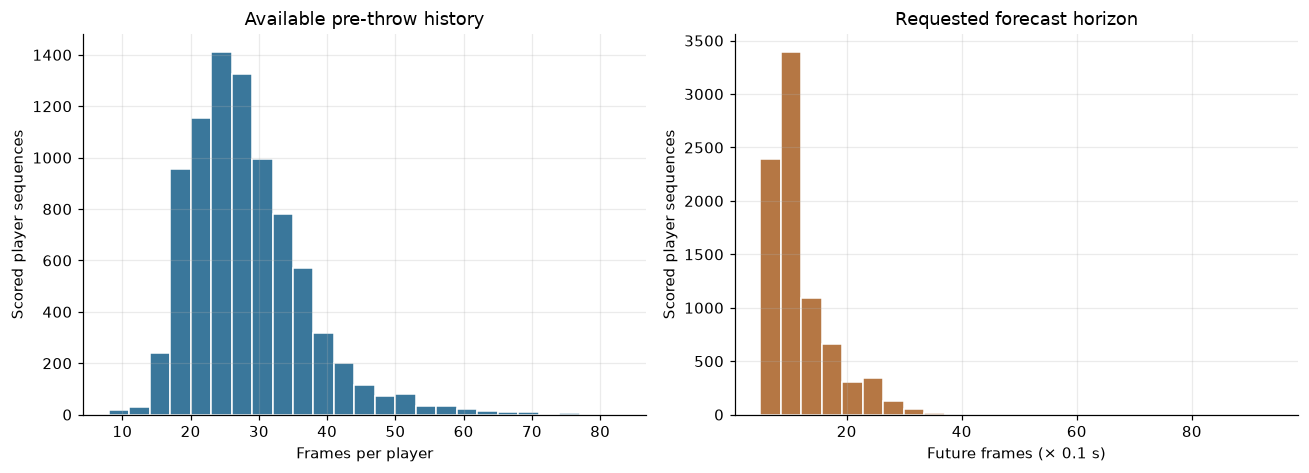

In [17]:
input_lengths = (
    input_sorted.groupby(PLAYER_KEYS, sort=False)
    .agg(input_frames=("frame_id", "nunique"), last_input_frame=("frame_id", "max"))
    .reset_index()
)
input_lengths = input_lengths.merge(
    last_input[PLAYER_KEYS + ["player_role", "player_to_predict", "num_frames_output"]],
    on=PLAYER_KEYS, validate="one_to_one"
)
output_lengths = (
    output_df.groupby(PLAYER_KEYS, sort=False)
    .agg(actual_output_frames=("frame_id", "nunique"), max_output_frame=("frame_id", "max"))
    .reset_index()
)
sequence_lengths = input_lengths.merge(output_lengths, on=PLAYER_KEYS, how="left", validate="one_to_one")
scored_lengths = sequence_lengths.loc[sequence_lengths["player_to_predict"]].copy()
scored_lengths["num_frames_output"] = pd.to_numeric(scored_lengths["num_frames_output"], errors="coerce")
scored_lengths["complete_target"] = (
    (scored_lengths["actual_output_frames"] == scored_lengths["num_frames_output"]) &
    (scored_lengths["max_output_frame"] == scored_lengths["num_frames_output"])
)
print("Scored player-sequence completeness:")
display(scored_lengths["complete_target"].value_counts(dropna=False).rename("sequences"))
print("\nLength summary (frames):")
display(scored_lengths[["input_frames", "num_frames_output", "actual_output_frames"]].describe())

fig, axs = plt.subplots(1, 2, figsize=(12, 4.4))
axs[0].hist(scored_lengths["input_frames"].dropna(), bins=25, color="#3a779b", edgecolor="white")
axs[0].set(title="Available pre-throw history", xlabel="Frames per player", ylabel="Scored player sequences")
axs[1].hist(scored_lengths["num_frames_output"].dropna(), bins=25, color="#b57744", edgecolor="white")
axs[1].set(title="Requested forecast horizon", xlabel="Future frames (× 0.1 s)", ylabel="Scored player sequences")
plt.tight_layout()
save_figure(fig, "03_sequence_lengths.png")
plt.show()

## Visible and scored players per play?


,observed_players,scored_players
count,2573.000000,2573.000000
mean,12.289157,3.263117
std,1.093752,1.285290
min,6.000000,1.000000
25%,12.000000,2.000000
50%,13.000000,3.000000
75%,13.000000,4.000000
max,17.000000,9.000000


Saved: C:\Users\jeast\Documents\UVA\ML_3\Project\eda_figures\04_players_per_play.png


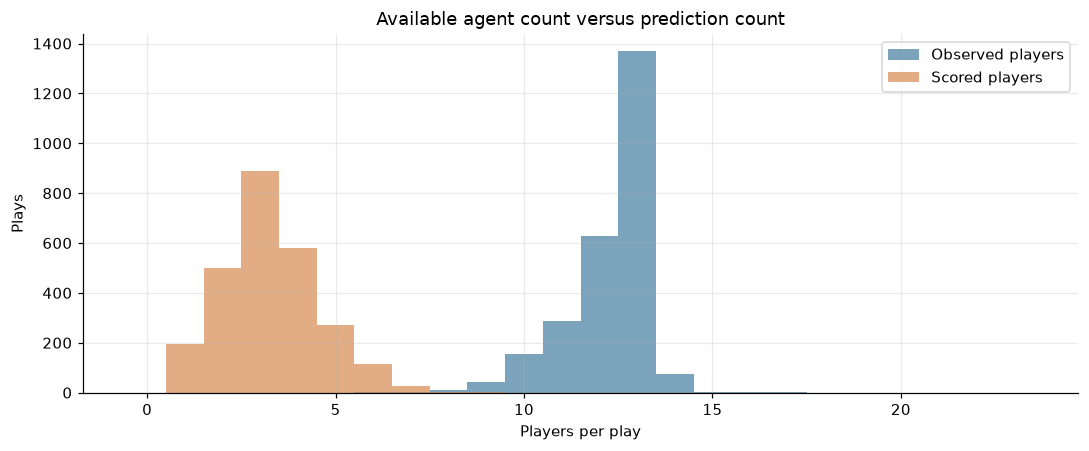

In [18]:
play_player_counts = (
    last_input.groupby(PLAY_KEYS, sort=False)
    .agg(observed_players=("nfl_id", "nunique"), scored_players=("player_to_predict", "sum"))
    .reset_index()
)
display(play_player_counts[["observed_players", "scored_players"]].describe())
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.hist(play_player_counts["observed_players"], bins=np.arange(0, 25) - .5,
        alpha=0.7, label="Observed players", color="#447ca0")
ax.hist(play_player_counts["scored_players"], bins=np.arange(0, 25) - .5,
        alpha=0.7, label="Scored players", color="#d68b52")
ax.set(xlabel="Players per play", ylabel="Plays", title="Available agent count versus prediction count")
ax.legend()
plt.tight_layout()
save_figure(fig, "04_players_per_play.png")
plt.show()

##  Player motion at the time of release


s                           a                     
                    count   mean median    std  count   mean median    std
player_role                                                               
Defensive Coverage  17159  3.897   3.80  1.765  17159  2.463   2.30  1.339
Targeted Receiver    2573  5.560   5.82  1.885   2573  3.094   3.04  1.584

Saved: C:\Users\jeast\Documents\UVA\ML_3\Project\eda_figures\05_release_motion_by_role.png


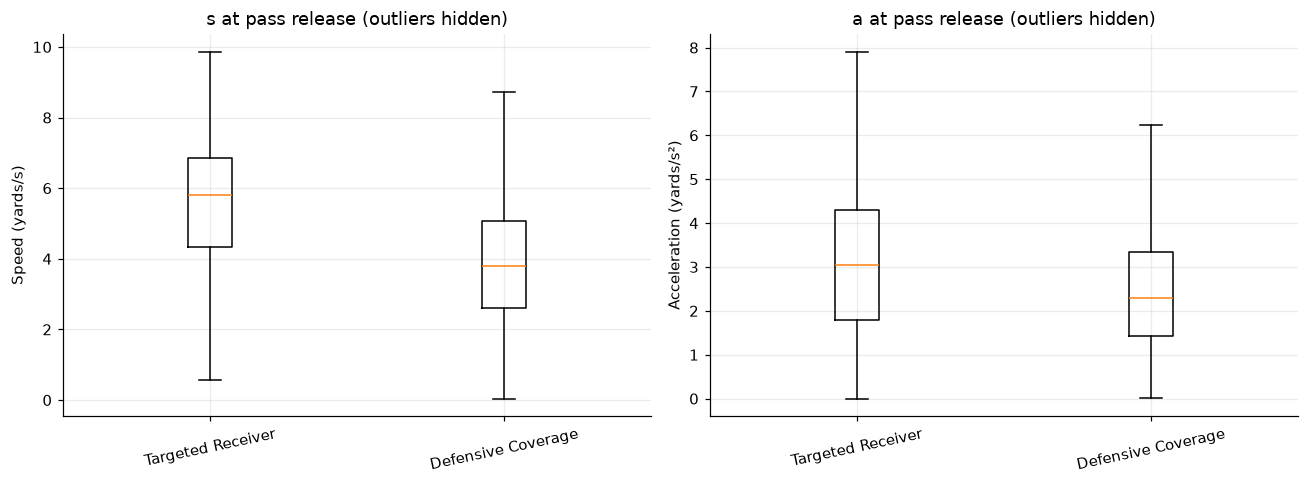

In [19]:
focus_roles = ["Targeted Receiver", "Defensive Coverage"]
motion = last_input[last_input["player_role"].isin(focus_roles)].copy()
for c in ["s", "a"]:
    motion[c] = pd.to_numeric(motion[c], errors="coerce")
display(motion.groupby("player_role")[["s", "a"]].agg(["count", "mean", "median", "std"]).round(3))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, ylabel in zip(axs, ["s", "a"], ["Speed (yards/s)", "Acceleration (yards/s²)"]):
    groups = [motion.loc[motion["player_role"] == r, col].dropna().values for r in focus_roles]
    ax.boxplot(groups, tick_labels=focus_roles, showfliers=False)
    ax.set(ylabel=ylabel, title=f"{col} at pass release (outliers hidden)")
    ax.tick_params(axis="x", rotation=12)
plt.tight_layout()
save_figure(fig, "05_release_motion_by_role.png")
plt.show()

## Making a field visual

In [20]:
# Optional explicit choice: provide both game and play ID, or leave as None.
EXAMPLE_GAME_ID = None
EXAMPLE_PLAY_ID = None

receiver_plays = last_input.loc[
    last_input["player_role"].eq("Targeted Receiver") & last_input["player_to_predict"], PLAY_KEYS
].drop_duplicates()
if EXAMPLE_GAME_ID is None or EXAMPLE_PLAY_ID is None:
    candidates = receiver_plays if not receiver_plays.empty else last_input[PLAY_KEYS].drop_duplicates()
    chosen = candidates.iloc[int(rng.integers(len(candidates)))]
else:
    candidates = last_input.loc[
        last_input["game_id"].eq(EXAMPLE_GAME_ID) & last_input["play_id"].eq(EXAMPLE_PLAY_ID), PLAY_KEYS
    ].drop_duplicates()
    if candidates.empty:
        raise ValueError("Selected game/play does not appear in the loaded weeks.")
    chosen = candidates.iloc[0]
example_week, example_game, example_play = (int(chosen[k]) for k in PLAY_KEYS)

play_in = input_sorted.loc[
    input_sorted["week"].eq(example_week) & input_sorted["game_id"].eq(example_game) & input_sorted["play_id"].eq(example_play)
].copy()
play_out = output_df.loc[
    output_df["week"].eq(example_week) & output_df["game_id"].eq(example_game) & output_df["play_id"].eq(example_play)
].copy()
print(f"Example: week {example_week}, game {example_game}, play {example_play}")
print(f"Observed players: {play_in['nfl_id'].nunique()} | Output players: {play_out['nfl_id'].nunique()}")

def draw_field(ax):
    ax.set_facecolor("#f5faf3")
    ax.add_patch(Rectangle((0, 0), 120, 53.3, color="#e4f0e2", zorder=0))
    ax.add_patch(Rectangle((0, 0), 10, 53.3, color="#cbdcce", alpha=.75, zorder=0))
    ax.add_patch(Rectangle((110, 0), 10, 53.3, color="#cbdcce", alpha=.75, zorder=0))
    for xline in range(10, 111, 10):
        ax.axvline(xline, color="white", linewidth=1.5, zorder=1)
    ax.set_xlim(0, 120)
    ax.set_ylim(0, 53.3)
    ax.set_aspect("equal", adjustable="box")
    ax.set(xlabel="Field x (yards)", ylabel="Field y (yards)")
    ax.grid(False)

Example: week 3, game 2023092500, play 1654
Observed players: 13 | Output players: 6


## Plot listed and future player trajectories


Saved: C:\Users\jeast\Documents\UVA\ML_3\Project\eda_figures\06_example_player_trajectories.png


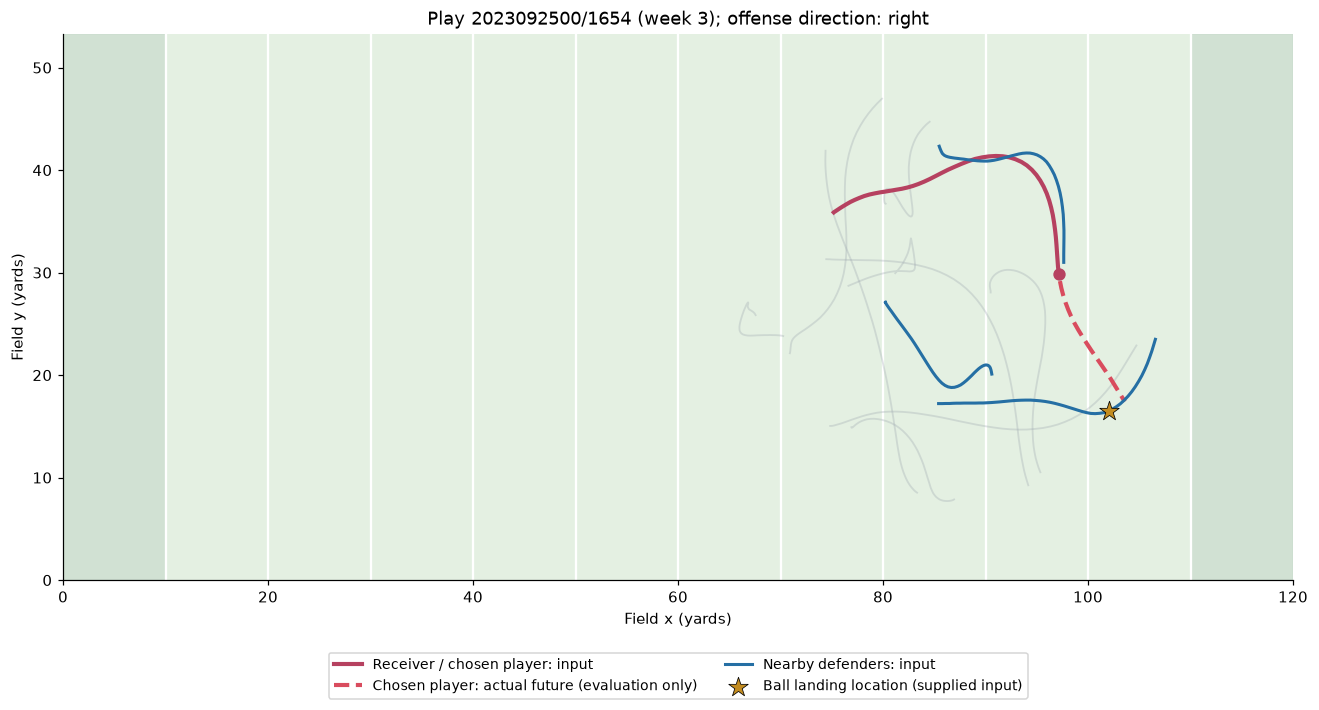

In [21]:
def plot_example_play(play_in, play_out):
    fig, ax = plt.subplots(figsize=(13, 6.2))
    draw_field(ax)
    for _, track in play_in.sort_values("frame_id").groupby("nfl_id"):
        ax.plot(track["x"], track["y"], color="#9da7af", alpha=.32, linewidth=1.2)
    recent = play_in.sort_values("frame_id").groupby("nfl_id").tail(1)
    rec = recent.loc[recent["player_role"].eq("Targeted Receiver") & recent["player_to_predict"]]
    if rec.empty:
        rec = recent.loc[recent["player_to_predict"]]
    rec = rec.iloc[0] if len(rec) else recent.iloc[0]
    rec_id = rec["nfl_id"]
    rec_track = play_in.loc[play_in["nfl_id"].eq(rec_id)].sort_values("frame_id")
    ax.plot(rec_track["x"], rec_track["y"], color="#b64160", linewidth=2.7, label="Receiver / chosen player: input")
    ax.scatter([rec["x"]], [rec["y"]], color="#b64160", s=50, zorder=5)
    rec_future = play_out.loc[play_out["nfl_id"].eq(rec_id)].sort_values("frame_id")
    if not rec_future.empty:
        ax.plot(rec_future["x"], rec_future["y"], "--", linewidth=2.7,
                color="#d94c5e", label="Chosen player: actual future (evaluation only)")
    defenses = recent.loc[recent["player_role"].eq("Defensive Coverage")].copy()
    if not defenses.empty:
        defenses["dist"] = np.hypot(defenses["x"] - rec["x"], defenses["y"] - rec["y"])
        for j, defender_id in enumerate(defenses.nsmallest(3, "dist")["nfl_id"]):
            track = play_in.loc[play_in["nfl_id"].eq(defender_id)].sort_values("frame_id")
            ax.plot(track["x"], track["y"], linewidth=2, color="#256fa4",
                    label="Nearby defenders: input" if j == 0 else None)
    if pd.notna(rec["ball_land_x"]) and pd.notna(rec["ball_land_y"]):
        ax.scatter([rec["ball_land_x"]], [rec["ball_land_y"]], marker="*", s=180,
                   color="#c38c20", edgecolors="black", linewidths=.5,
                   label="Ball landing location (supplied input)", zorder=6)
    direction = rec.get("play_direction", "unknown")
    ax.set_title(f"Play {example_game}/{example_play} (week {example_week}); offense direction: {direction}")
    ax.legend(loc="upper center", bbox_to_anchor=(.5, -.12), ncol=2, fontsize=9)
    plt.tight_layout()
    return fig, rec_id

example_fig, example_receiver_id = plot_example_play(play_in, play_out)
save_figure(example_fig, "06_example_player_trajectories.png")
plt.show()

## Timeline view of a player's x/y coordinates


Saved: C:\Users\jeast\Documents\UVA\ML_3\Project\eda_figures\07_example_trajectory_timeseries.png


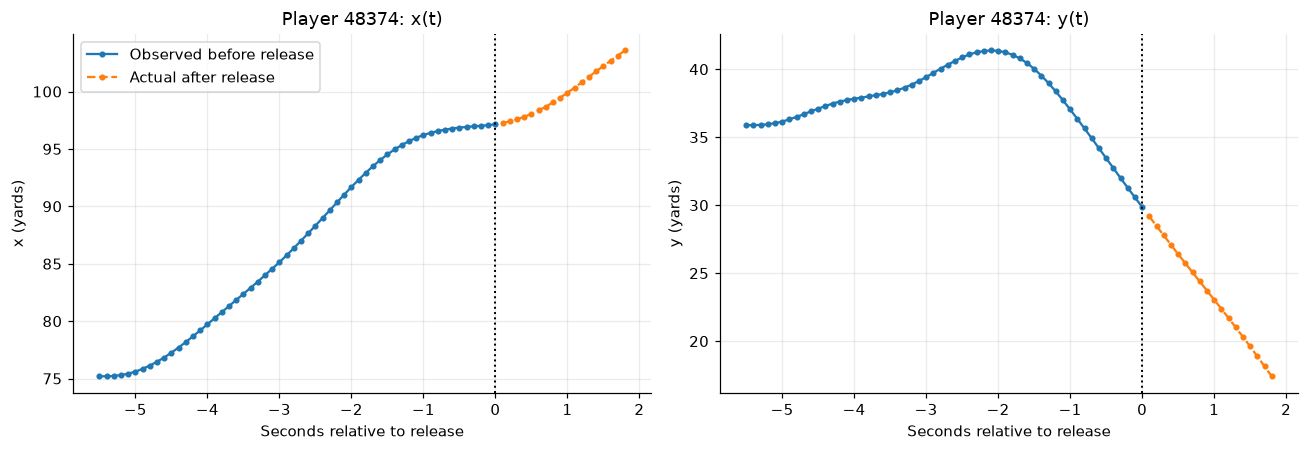

In [22]:
hist = play_in.loc[play_in["nfl_id"].eq(example_receiver_id)].sort_values("frame_id").copy()
futr = play_out.loc[play_out["nfl_id"].eq(example_receiver_id)].sort_values("frame_id").copy()
hist["relative_t_s"] = (hist["frame_id"] - hist["frame_id"].max()) / FPS
futr["relative_t_s"] = futr["frame_id"] / FPS
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, col in zip(axs, ["x", "y"]):
    ax.plot(hist["relative_t_s"], hist[col], "o-", markersize=3, label="Observed before release")
    if not futr.empty:
        ax.plot(futr["relative_t_s"], futr[col], "o--", markersize=3, label="Actual after release")
    ax.axvline(0, color="black", linestyle=":", linewidth=1.3)
    ax.set(xlabel="Seconds relative to release", ylabel=f"{col} (yards)", title=f"Player {example_receiver_id}: {col}(t)")
axs[0].legend()
plt.tight_layout()
save_figure(fig, "07_example_trajectory_timeseries.png")
plt.show()

## Nearest-defender distance at time of release

Targeted receivers with >=1 defensive coverage player: 2573


,distance (yards)
count,2573.000000
mean,4.389834
std,3.118313
min,0.297321
25%,2.008009
50%,3.691314
75%,5.864000
max,19.123611


Saved: C:\Users\jeast\Documents\UVA\ML_3\Project\eda_figures\08_receiver_defender_separation.png


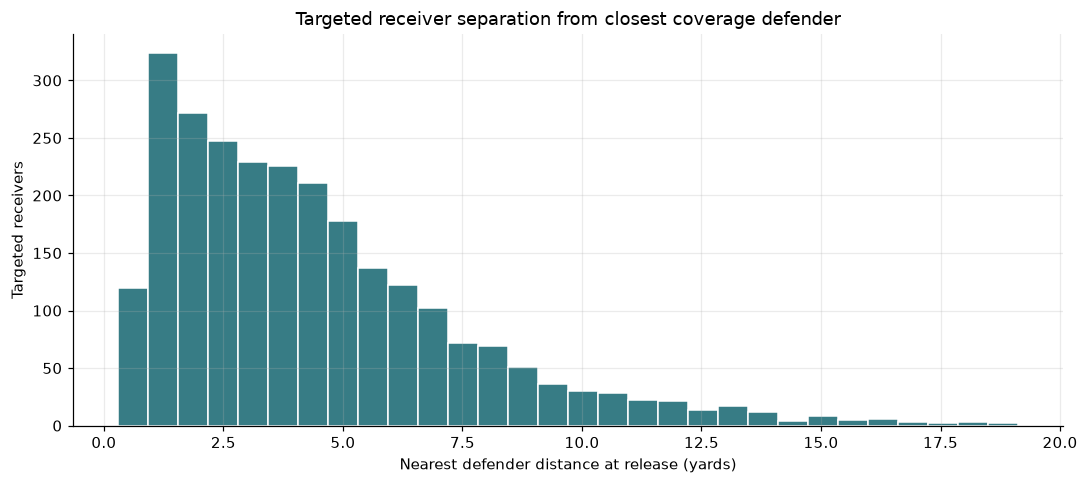

In [23]:
def nearest_defender_features(last_positions):
    records = []
    for keys, players in last_positions.groupby(PLAY_KEYS, sort=False):
        receivers = players.loc[players["player_role"].eq("Targeted Receiver") & players["player_to_predict"]]
        defenders = players.loc[players["player_role"].eq("Defensive Coverage")]
        if receivers.empty or defenders.empty:
            continue
        D = defenders[["x", "y"]].to_numpy(dtype=float)
        dids = defenders["nfl_id"].to_numpy()
        for r in receivers.itertuples(index=False):
            distances = np.hypot(D[:, 0] - r.x, D[:, 1] - r.y)
            if not np.isfinite(distances).any():
                continue
            ix = int(np.nanargmin(distances))
            records.append({
                **dict(zip(PLAY_KEYS, keys)),
                "nfl_id": r.nfl_id,
                "nearest_defender_id": dids[ix],
                "nearest_defender_yards": float(distances[ix]),
                "num_coverage_defenders": len(defenders),
            })
    return pd.DataFrame.from_records(records, columns=PLAYER_KEYS + [
        "nearest_defender_id", "nearest_defender_yards", "num_coverage_defenders"
    ])

receiver_separation = nearest_defender_features(last_input)
print("Targeted receivers with >=1 defensive coverage player:", len(receiver_separation))
display(receiver_separation["nearest_defender_yards"].describe().to_frame("distance (yards)"))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(receiver_separation["nearest_defender_yards"].dropna(), bins=30,
        color="#377c85", edgecolor="white")
ax.set(xlabel="Nearest defender distance at release (yards)", ylabel="Targeted receivers",
       title="Targeted receiver separation from closest coverage defender")
plt.tight_layout()
save_figure(fig, "08_receiver_defender_separation.png")
plt.show()

## Baselines

In [24]:
# Compute previous OBSERVED input row per player; frame gaps are handled explicitly.
previous = input_sorted.groupby(PLAYER_KEYS, sort=False)[["x", "y", "frame_id"]].shift(1)
previous.columns = ["prev_x", "prev_y", "prev_frame_id"]
input_with_prev = pd.concat([input_sorted, previous], axis=1)
release = input_with_prev.groupby(PLAYER_KEYS, sort=False).tail(1).copy()
release = release.loc[release["player_to_predict"]].copy()
release["frame_gap"] = release["frame_id"] - release["prev_frame_id"]
valid_history = (
    release["prev_x"].notna() & release["prev_y"].notna() & release["frame_gap"].gt(0)
)
release["vx_per_frame"] = np.where(
    valid_history, (release["x"] - release["prev_x"]) / release["frame_gap"], 0.0
)
release["vy_per_frame"] = np.where(
    valid_history, (release["y"] - release["prev_y"]) / release["frame_gap"], 0.0
)
release = release.rename(columns={
    "x": "release_x", "y": "release_y", "frame_id": "release_frame_id",
})
release_cols = PLAYER_KEYS + ["player_role", "player_side", "release_x", "release_y",
                              "release_frame_id", "vx_per_frame", "vy_per_frame",
                              "num_frames_output", "ball_land_x", "ball_land_y"]
scoring = output_df.merge(
    release[release_cols], on=PLAYER_KEYS, how="inner", validate="many_to_one"
)
if scoring.empty:
    raise ValueError("No output frames matched scored player sequences. Inspect IDs and files.")
# Output frame_id starts again at 1; relative to last input step 0, future displacement uses k frames.
k = scoring["frame_id"].to_numpy(dtype=float)
scoring["last_x"] = scoring["release_x"]
scoring["last_y"] = scoring["release_y"]
scoring["cv_x"] = scoring["release_x"] + k * scoring["vx_per_frame"]
scoring["cv_y"] = scoring["release_y"] + k * scoring["vy_per_frame"]

print(f"Scored output frames matched: {len(scoring):,} / {len(output_df):,} total output rows")
print("Scored player sequences lacking two valid observed frames:", int((~valid_history).sum()))
display(scoring[["week", "game_id", "play_id", "nfl_id", "frame_id",
                 "x", "y", "last_x", "last_y", "cv_x", "cv_y"]].head(6))

Scored output frames matched: 100,348 / 100,348 total output rows
Scored player sequences lacking two valid observed frames: 0


,week,game_id,play_id,nfl_id,frame_id,x,y,last_x,last_y,cv_x,cv_y
0,1,2023090700,101,46137,1,56.22,17.28,55.82,17.67,56.19,17.31
1,1,2023090700,101,46137,2,56.63,16.88,55.82,17.67,56.56,16.95
2,1,2023090700,101,46137,3,57.06,16.46,55.82,17.67,56.93,16.59
3,1,2023090700,101,46137,4,57.48,16.02,55.82,17.67,57.30,16.23
4,1,2023090700,101,46137,5,57.91,15.56,55.82,17.67,57.67,15.87
5,1,2023090700,101,46137,6,58.34,15.10,55.82,17.67,58.04,15.51


## RMSE, ADE, and FDE

In [25]:
for model, xc, yc in [("last", "last_x", "last_y"), ("cv", "cv_x", "cv_y")]:
    scoring[f"sqerr_{model}"] = (scoring[xc] - scoring["x"])**2 + (scoring[yc] - scoring["y"])**2
    scoring[f"dist_{model}"] = np.sqrt(scoring[f"sqerr_{model}"])

def evaluate_subset(df):
    if df.empty:
        return pd.DataFrame(columns=["baseline", "RMSE_yards", "ADE_yards", "FDE_yards", "frames", "player_sequences"])
    final_rows = df.sort_values("frame_id").groupby(PLAYER_KEYS, sort=False).tail(1)
    rows = []
    for baseline in ["last", "cv"]:
        rows.append({
            "baseline": "Last position" if baseline == "last" else "Constant velocity",
            "RMSE_yards": np.sqrt(df[f"sqerr_{baseline}"].mean() / 2),
            "ADE_yards": df[f"dist_{baseline}"].mean(),
            "FDE_yards": final_rows[f"dist_{baseline}"].mean(),
            "frames": len(df),
            "player_sequences": len(final_rows),
        })
    return pd.DataFrame(rows)

baseline_metrics = evaluate_subset(scoring)
display(baseline_metrics.round(4))
print("Note: Baselines have not been trained or optimized; these are descriptive reference results.")

,baseline,RMSE_yards,ADE_yards,FDE_yards,frames,player_sequences
0,Last position,4.2152,4.1779,6.0635,100348,8396
1,Constant velocity,2.0776,1.5371,2.7488,100348,8396


Note: Baselines have not been trained or optimized; these are descriptive reference results.


## forecasting error by player role

,role,baseline,RMSE_yards,ADE_yards,FDE_yards,frames,player_sequences
1,Defensive Coverage,Constant velocity,2.165,1.645,2.976,71605,5823
0,Defensive Coverage,Last position,4.026,3.985,5.883,71605,5823
3,Targeted Receiver,Constant velocity,1.840,1.269,2.235,28743,2573
2,Targeted Receiver,Last position,4.654,4.659,6.473,28743,2573


Saved: C:\Users\jeast\Documents\UVA\ML_3\Project\eda_figures\09_baseline_rmse_by_role.png


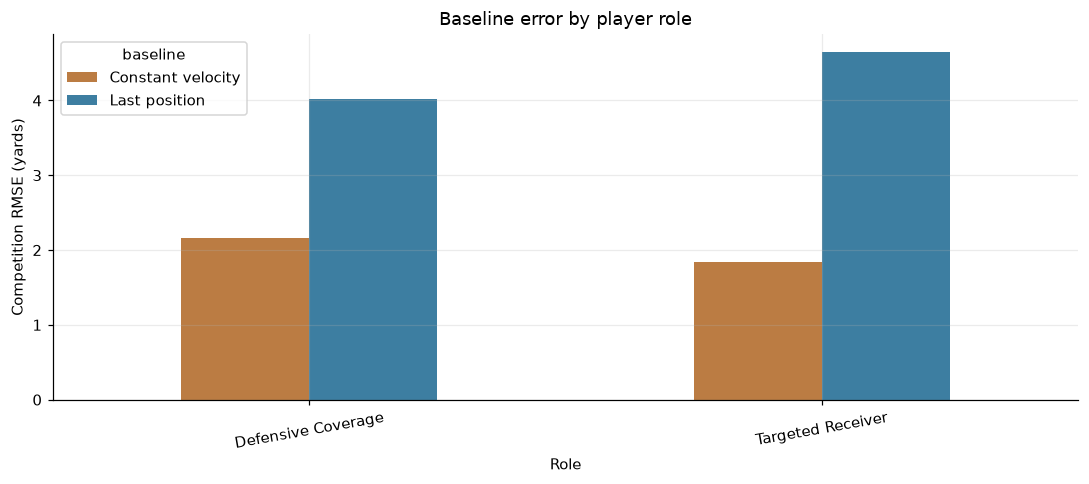

In [26]:
role_results = []
for role, subset in scoring.groupby("player_role", dropna=False):
    result = evaluate_subset(subset)
    result.insert(0, "role", role)
    role_results.append(result)
role_metrics = pd.concat(role_results, ignore_index=True)
display(role_metrics.sort_values(["role", "baseline"]).round(3))

plot_roles = role_metrics[role_metrics["role"].isin(focus_roles)]
if not plot_roles.empty:
    pivot = plot_roles.pivot(index="role", columns="baseline", values="RMSE_yards")
    ax = pivot.plot.bar(rot=10, figsize=(10, 4.5), color=["#bb7c43", "#3d7ea1"])
    ax.set(ylabel="Competition RMSE (yards)", xlabel="Role", title="Baseline error by player role")
    plt.tight_layout()
    save_figure(ax.figure, "09_baseline_rmse_by_role.png")
    plt.show()

## Error as forecast horizon increases

Saved: C:\Users\jeast\Documents\UVA\ML_3\Project\eda_figures\10_error_by_forecast_horizon.png


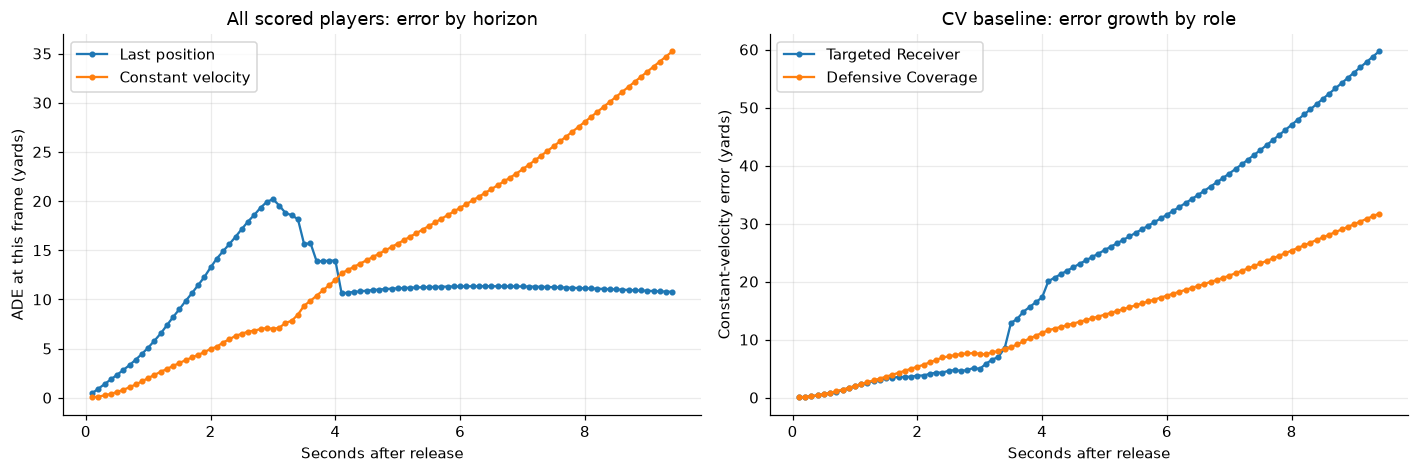

In [27]:
horizon_summary = (
    scoring.groupby("frame_id", sort=True)[["dist_last", "dist_cv"]]
    .agg(["mean", "count"])
)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
for name, column in [("Last position", "dist_last"), ("Constant velocity", "dist_cv")]:
    means = scoring.groupby("frame_id")[column].mean()
    axs[0].plot(means.index / FPS, means.values, marker=".", label=name)
axs[0].set(xlabel="Seconds after release", ylabel="ADE at this frame (yards)",
           title="All scored players: error by horizon")
axs[0].legend()
for role in focus_roles:
    part = scoring[scoring["player_role"].eq(role)]
    means = part.groupby("frame_id")["dist_cv"].mean()
    if len(means):
        axs[1].plot(means.index / FPS, means.values, marker=".", label=role)
axs[1].set(xlabel="Seconds after release", ylabel="Constant-velocity error (yards)",
           title="CV baseline: error growth by role")
axs[1].legend()
plt.tight_layout()
save_figure(fig, "10_error_by_forecast_horizon.png")
plt.show()

## receiver–defender separation relation to error

,separation_bin,baseline,RMSE_yards,ADE_yards,FDE_yards,frames,player_sequences
0,<2 yd,Last position,5.618,5.967,8.719,8569,639
1,<2 yd,Constant velocity,1.591,1.482,2.876,8569,639
2,2–5 yd,Last position,4.645,4.627,6.451,11913,1081
3,2–5 yd,Constant velocity,1.412,1.260,2.356,11913,1081
4,5–10 yd,Last position,3.497,3.437,4.887,6763,689
5,5–10 yd,Constant velocity,2.741,1.169,1.721,6763,689
6,>=10 yd,Last position,2.866,2.943,4.527,1498,164
7,>=10 yd,Constant velocity,0.856,0.573,1.093,1498,164


Saved: C:\Users\jeast\Documents\UVA\ML_3\Project\eda_figures\11_receiver_proximity_and_error.png


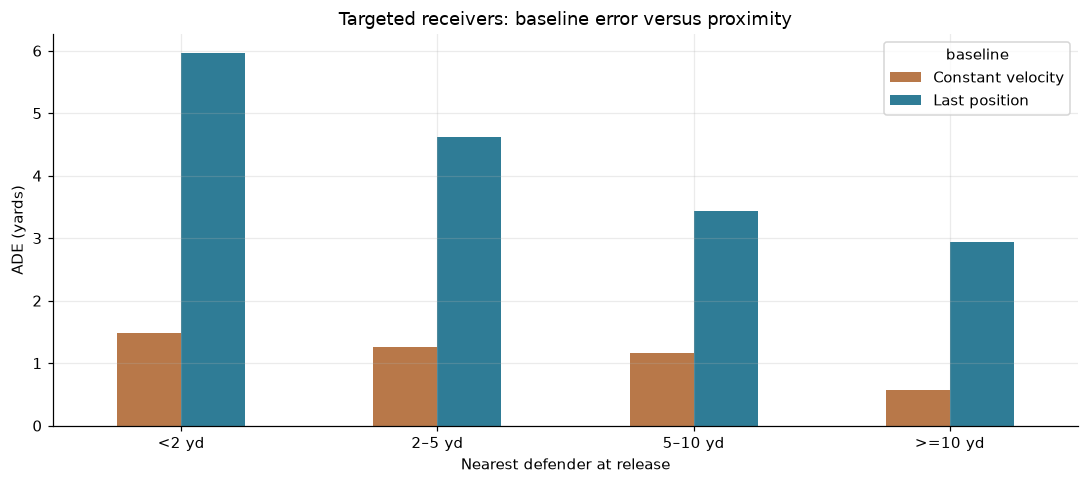

In [28]:
receiver_scored = scoring.loc[scoring["player_role"].eq("Targeted Receiver")].merge(
    receiver_separation[PLAYER_KEYS + ["nearest_defender_yards"]],
    on=PLAYER_KEYS, how="left", validate="many_to_one"
)
bins = [-np.inf, 2.0, 5.0, 10.0, np.inf]
labels = ["<2 yd", "2–5 yd", "5–10 yd", ">=10 yd"]
receiver_scored["separation_bin"] = pd.cut(
    receiver_scored["nearest_defender_yards"], bins=bins, labels=labels, right=False
)
sep_rows = []
for band, part in receiver_scored.groupby("separation_bin", observed=True):
    for _, metric in evaluate_subset(part).iterrows():
        sep_rows.append({"separation_bin": str(band), **metric.to_dict()})
sep_metrics = pd.DataFrame(sep_rows)
if sep_metrics.empty:
    print("No targeted receiver observations with eligible defenders in the selected weeks.")
else:
    display(sep_metrics.round(3))
    pivot = sep_metrics.pivot(index="separation_bin", columns="baseline", values="ADE_yards")
    pivot = pivot.reindex(labels)
    ax = pivot.plot(kind="bar", rot=0, figsize=(10, 4.5), color=["#b87849", "#2f7c96"])
    ax.set(xlabel="Nearest defender at release", ylabel="ADE (yards)",
           title="Targeted receivers: baseline error versus proximity")
    plt.tight_layout()
    save_figure(ax.figure, "11_receiver_proximity_and_error.png")
    plt.show()

## Paired game-level bootstrap comparison 

Observed CV - last-position RMSE: -2.1376 yards
Paired game bootstrap 95% interval: [-2.6406, -1.3839] yards
Game clusters: 48; bootstrap draws: 500
Saved: C:\Users\jeast\Documents\UVA\ML_3\Project\eda_figures\12_game_bootstrap_rmse_difference.png


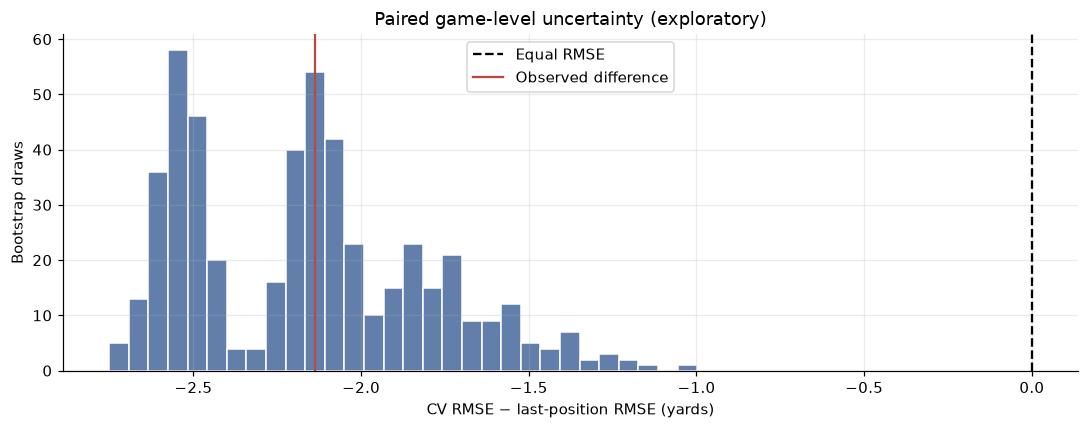

In [29]:
N_BOOTSTRAPS = 500
GAME_KEYS = ["week", "game_id"]
game_sums = (
    scoring.groupby(GAME_KEYS, sort=False)
    .agg(n=("sqerr_last", "size"), last_sq=("sqerr_last", "sum"), cv_sq=("sqerr_cv", "sum"))
    .reset_index()
)
if len(game_sums) < 2:
    print("Bootstrap skipped: need observations from at least two games.")
else:
    per_game = game_sums[["n", "last_sq", "cv_sq"]].to_numpy(dtype=float)
    sample_idx = rng.integers(0, len(per_game), size=(N_BOOTSTRAPS, len(per_game)))
    sampled = per_game[sample_idx].sum(axis=1)
    rmse_last = np.sqrt(sampled[:, 1] / (2 * sampled[:, 0]))
    rmse_cv = np.sqrt(sampled[:, 2] / (2 * sampled[:, 0]))
    delta = rmse_cv - rmse_last
    observed_delta = float(baseline_metrics.loc[baseline_metrics["baseline"].eq("Constant velocity"), "RMSE_yards"].iloc[0] -
                           baseline_metrics.loc[baseline_metrics["baseline"].eq("Last position"), "RMSE_yards"].iloc[0])
    ci_lo, ci_hi = np.quantile(delta, [.025, .975])
    print(f"Observed CV - last-position RMSE: {observed_delta:+.4f} yards")
    print(f"Paired game bootstrap 95% interval: [{ci_lo:+.4f}, {ci_hi:+.4f}] yards")
    print(f"Game clusters: {len(per_game):,}; bootstrap draws: {N_BOOTSTRAPS}")
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(delta, bins=30, color="#627fab", edgecolor="white")
    ax.axvline(0, color="black", linestyle="--", label="Equal RMSE")
    ax.axvline(observed_delta, color="#b54c3f", label="Observed difference")
    ax.set(xlabel="CV RMSE − last-position RMSE (yards)", ylabel="Bootstrap draws",
           title="Paired game-level uncertainty (exploratory)")
    ax.legend()
    plt.tight_layout()
    save_figure(fig, "12_game_bootstrap_rmse_difference.png")
    plt.show()

## Summaries

In [30]:
if SAVE_FIGURES:
    baseline_metrics.to_csv(FIG_DIR / "baseline_metrics.csv", index=False)
    role_metrics.to_csv(FIG_DIR / "role_metrics.csv", index=False)
    sequence_lengths.to_csv(FIG_DIR / "sequence_lengths.csv", index=False)
    receiver_separation.to_csv(FIG_DIR / "receiver_release_separation.csv", index=False)
    if not sep_metrics.empty:
        sep_metrics.to_csv(FIG_DIR / "separation_band_metrics.csv", index=False)

print("EDA completed for weeks:", selected_weeks)
print("Scored player sequences:", scoring[PLAYER_KEYS].drop_duplicates().shape[0])
print("Scored future frames:", len(scoring))
print("\nKey reference metrics (yards):")
display(baseline_metrics.round(4))
print("\nModeling priority: preserve strict time/weekly grouping and reuse these exact scoring definitions.")
print("Output folder:", FIG_DIR.resolve() if SAVE_FIGURES else "Figure saving disabled")

EDA completed for weeks: [1, 2, 3]
Scored player sequences: 8396
Scored future frames: 100348

Key reference metrics (yards):


,baseline,RMSE_yards,ADE_yards,FDE_yards,frames,player_sequences
0,Last position,4.2152,4.1779,6.0635,100348,8396
1,Constant velocity,2.0776,1.5371,2.7488,100348,8396



Modeling priority: preserve strict time/weekly grouping and reuse these exact scoring definitions.
Output folder: C:\Users\jeast\Documents\UVA\ML_3\Project\eda_figures
